Imports das bibliotecas

In [1]:
import os
from pathlib import Path
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

Definir caminhos e classe de Dataset customizada

In [ ]:
# Versao fixa para manter os dados das experiencias reproduziveis.
DATASET_HANDLE = "mostafaabla/garbage-classification/versions/1"
path = Path(kagglehub.dataset_download(DATASET_HANDLE))
print("Path to dataset files:", path)
DATASET_PATH = path / "garbage_classification"
EXPECTED_CLASSES = {
    "battery", "biological", "brown-glass", "cardboard", "clothes", "green-glass",
    "metal", "paper", "plastic", "shoes", "trash", "white-glass",
}
if not DATASET_PATH.is_dir():
    raise FileNotFoundError(f"Diretorio das classes nao encontrado: {DATASET_PATH}")
if {p.name for p in DATASET_PATH.iterdir() if p.is_dir()} != EXPECTED_CLASSES:
    raise ValueError(f"Classes inesperadas em {DATASET_PATH}")

def fix_path(image_path):
    # Reutilizar features com caminhos de outra maquina, sempre na versao fixa.
    parts = str(image_path).replace("\\", "/").split("/")
    resolved_path = DATASET_PATH.joinpath(*parts[-2:])
    if not resolved_path.is_file():
        raise FileNotFoundError(f"Imagem nao encontrada: {resolved_path}")
    return str(resolved_path)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Definir device (GPU se disponível, senão CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"A usar o dispositivo: {device}")

# Dataset customizado em PyTorch para percorrer a estrutura de pastas
class GarbageDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []
        
        # Guardar os nomes das pastas como classes
        self.class_names = sorted([d for d in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, d))])
        self.class_to_idx = {class_name: i for i, class_name in enumerate(self.class_names)}
        
        for class_name in self.class_names:
            class_dir = os.path.join(root_dir, class_name)
            for img_name in os.listdir(class_dir):
                if img_name.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp')):
                    self.image_paths.append(os.path.join(class_dir, img_name))
                    self.labels.append(self.class_to_idx[class_name])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]
        
        if self.transform:
            image = self.transform(image)
            
        return image, label, img_path

# EDA e protocolo experimental comum — Experiências A e B

Esta secção executa apenas inspeção, gráficos, hashing e preparação de manifestos.
**Parar antes das células históricas de modelos; não utilizar “Run All” nesta fase.**
A implementação científica original abaixo mantém-se intacta e ainda não consome os novos manifestos.

Fonte: [Kaggle — Garbage Classification (12 classes)](https://www.kaggle.com/datasets/mostafaabla/garbage-classification/versions/1),
`mostafaabla/garbage-classification/versions/1`. A raiz contém as pastas das classes.
Nenhuma imagem é copiada, removida ou alterada. As análises globais seguintes são uma auditoria de
qualidade e desenho do protocolo anterior ao treino; não serão utilizadas para escolher modelos a partir do teste.

In [3]:
import sys
import pandas as pd
from IPython.display import display, Markdown

EDA_PROJECT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
if str(EDA_PROJECT / "notebooks") not in sys.path:
    sys.path.insert(0, str(EDA_PROJECT / "notebooks"))
from dataset_protocol import (
    scan_dataset, exact_groups, visual_candidates, split_groups, write_manifests,
    load_pool_views, resolve_image, MANIFEST_DIR, SEED,
)

eda_records = scan_dataset(DATASET_PATH)
eda_df = pd.DataFrame(eda_records)
eda_counts = eda_df.groupby("label").size().rename("imagens").to_frame()
eda_counts["percentagem"] = 100 * eda_counts["imagens"] / len(eda_df)
display(Markdown(f"**Dataset:** Garbage Classification; **versão:** 1; **origem:** Kaggle; "
                 f"**imagens:** {len(eda_df):,}; **classes:** {len(eda_counts)}."))
display(eda_counts.round(3))

EDA: 1000/15515 imagens


EDA: 2000/15515 imagens


EDA: 3000/15515 imagens


EDA: 4000/15515 imagens


EDA: 5000/15515 imagens


...

EDA: 13000/15515 imagens


EDA: 14000/15515 imagens


EDA: 15000/15515 imagens


**Dataset:** Garbage Classification; **versão:** 1; **origem:** Kaggle; **imagens:** 15,515; **classes:** 12.

,imagens,percentagem
label,,
battery,945,6.091
biological,985,6.349
brown-glass,607,3.912
cardboard,891,5.743
clothes,5325,34.322
green-glass,629,4.054
metal,769,4.956
paper,1050,6.768
plastic,865,5.575


## Distribuição das classes e desequilíbrio

As contagens incluem todos os ficheiros, incluindo cópias exatas. As percentagens usam como denominador
o total do dataset. A razão maior/minor quantifica o desequilíbrio; não se aplica balanceamento.
A futura comparação usará **Macro-F1**, dando igual peso às 12 classes, em conjunto com métricas por classe.

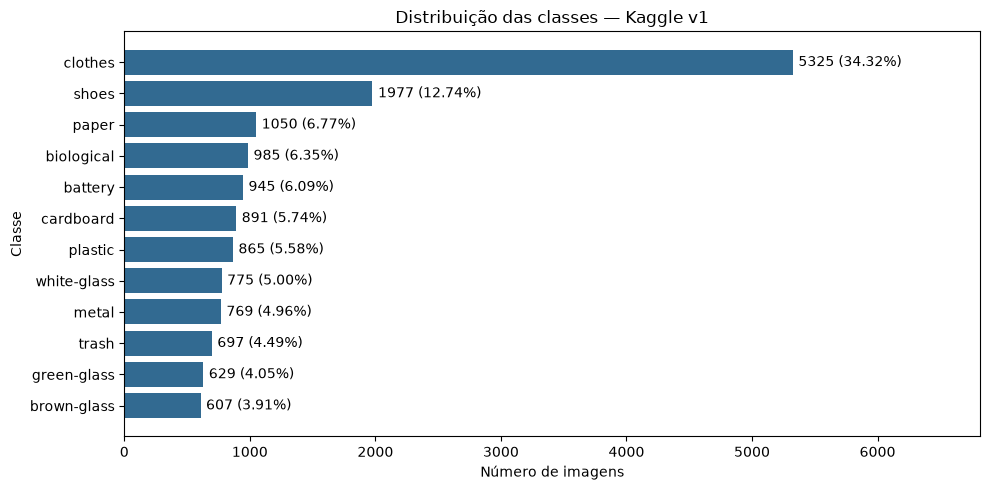

A classe maioritária é **clothes** (34.32%) e a minoritária é **brown-glass** (3.91%). A razão é **8.77:1**. Uma accuracy global elevada pode ocultar resultados fracos nas classes menos representadas; a distribuição do pool inicial será estratificada, sem alterar a frequência dos dados por balanceamento.

In [4]:
eda_ordered = eda_counts.sort_values("imagens")
fig, ax = plt.subplots(figsize=(10, 5))
eda_bars = ax.barh(eda_ordered.index, eda_ordered["imagens"], color="#326a91")
ax.bar_label(eda_bars, labels=[f"{n} ({pct:.2f}%)" for n, pct in eda_ordered.itertuples(index=False)], padding=4)
ax.set(xlabel="Número de imagens", ylabel="Classe", title="Distribuição das classes — Kaggle v1")
ax.set_xlim(0, eda_counts["imagens"].max() * 1.28)
fig.tight_layout()
fig.savefig(EDA_PROJECT / "artifacts" / "eda" / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
eda_major = eda_counts["imagens"].idxmax()
eda_minor = eda_counts["imagens"].idxmin()
display(Markdown(
    f"A classe maioritária é **{eda_major}** ({eda_counts.loc[eda_major, 'percentagem']:.2f}%) e a "
    f"minoritária é **{eda_minor}** ({eda_counts.loc[eda_minor, 'percentagem']:.2f}%). "
    f"A razão é **{eda_counts.loc[eda_major, 'imagens'] / eda_counts.loc[eda_minor, 'imagens']:.2f}:1**. "
    "Uma accuracy global elevada pode ocultar resultados fracos nas classes menos representadas; "
    "a distribuição do pool inicial será estratificada, sem alterar a frequência dos dados por balanceamento."
))

## Dimensões, resoluções, aspect ratios, formatos e integridade

Cada imagem passa por `Pillow.verify()` e descodificação completa (`load()`). São registados largura,
altura, razão largura/altura, formato real e modo de cor. Erros são apresentados e impedem a geração
de splits, em vez de excluir silenciosamente ficheiros. A cache em `artifacts/eda/` reutiliza o resultado
quando caminho relativo, tamanho e `mtime_ns` não mudam; apagar essa cache força uma nova auditoria completa.

**Imagens ilegíveis/corrompidas detetadas:** 0.

,relative_path,error


,width,height,aspect_ratio
count,15515.000,15515.000,15515.000
mean,349.822,351.706,1.084
std,117.549,149.418,0.352
min,51.000,100.000,0.128
5%,194.000,177.000,0.665
25%,234.000,224.000,0.750
50%,400.000,384.000,1.000
75%,400.000,533.000,1.333
95%,512.000,534.000,1.651
max,888.000,936.000,5.020


**Resoluções distintas:** 892; abaixo, as 15 mais frequentes.

,,imagens
width,height,
400,533,2590
512,384,2358
225,225,2004
400,534,1077
275,183,691
259,194,550
533,400,388
400,711,300
194,259,230


imagens
extension format mode         
.jpg      JPEG   RGB     15481
          PNG    P          34

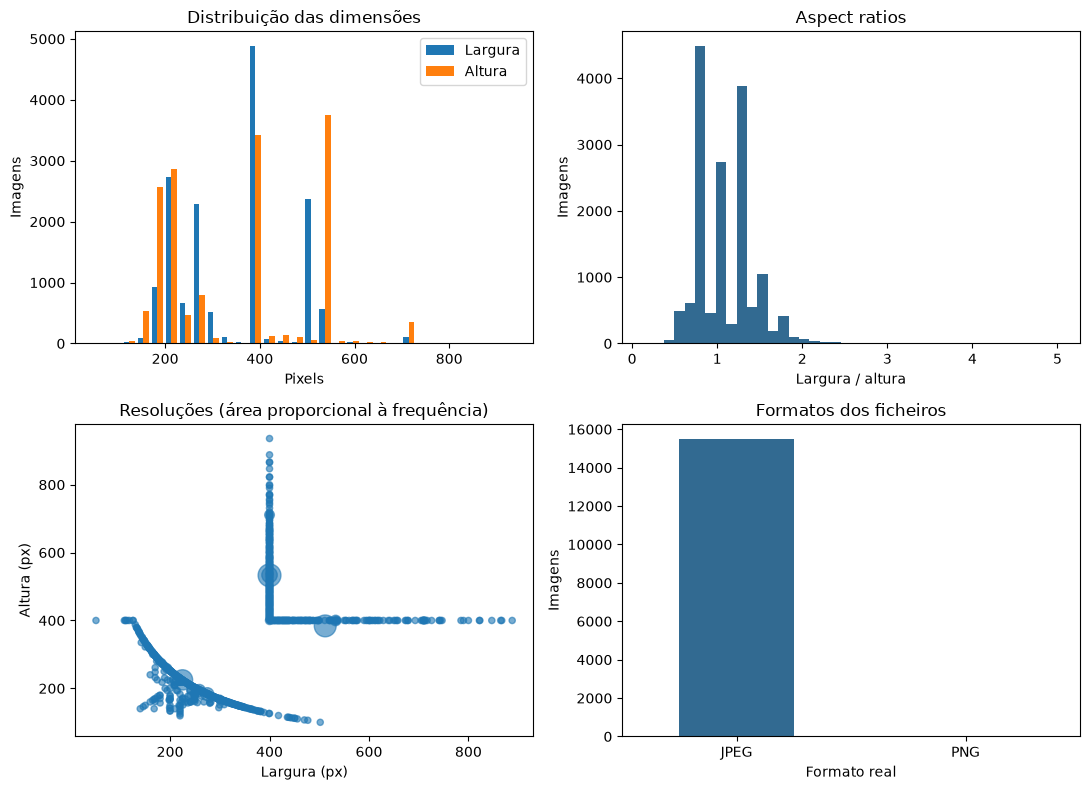

In [5]:
eda_errors = eda_df.loc[eda_df["error"] != "", ["relative_path", "error"]]
display(Markdown(f"**Imagens ilegíveis/corrompidas detetadas:** {len(eda_errors)}."))
display(eda_errors)
eda_valid = eda_df.loc[eda_df["error"] == ""].copy()
eda_valid[["width", "height", "aspect_ratio"]] = eda_valid[["width", "height", "aspect_ratio"]].apply(pd.to_numeric)
display(eda_valid[["width", "height", "aspect_ratio"]].describe(percentiles=[.05, .25, .5, .75, .95]).round(3))
eda_resolutions = eda_valid.groupby(["width", "height"]).size().rename("imagens").sort_values(ascending=False)
display(Markdown(f"**Resoluções distintas:** {len(eda_resolutions)}; abaixo, as 15 mais frequentes."))
display(eda_resolutions.head(15).to_frame())
eda_valid["extension"] = eda_valid["relative_path"].map(lambda p: Path(p).suffix.lower())
display(eda_valid.groupby(["extension", "format", "mode"]).size().rename("imagens").to_frame())

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].hist([eda_valid["width"], eda_valid["height"]], bins=30, label=["Largura", "Altura"])
axes[0, 0].set(xlabel="Pixels", ylabel="Imagens", title="Distribuição das dimensões")
axes[0, 0].legend()
axes[0, 1].hist(eda_valid["aspect_ratio"], bins=40, color="#326a91")
axes[0, 1].set(xlabel="Largura / altura", ylabel="Imagens", title="Aspect ratios")
eda_resolution_frame = eda_resolutions.reset_index()
axes[1, 0].scatter(eda_resolution_frame["width"], eda_resolution_frame["height"],
                   s=20 + 250 * eda_resolution_frame["imagens"] / eda_resolution_frame["imagens"].max(), alpha=.6)
axes[1, 0].set(xlabel="Largura (px)", ylabel="Altura (px)", title="Resoluções (área proporcional à frequência)")
eda_valid.groupby("format").size().plot.bar(ax=axes[1, 1], color="#326a91", rot=0)
axes[1, 1].set(xlabel="Formato real", ylabel="Imagens", title="Formatos dos ficheiros")
fig.tight_layout()
fig.savefig(EDA_PROJECT / "artifacts" / "eda" / "image_dimensions.png", dpi=150, bbox_inches="tight")
plt.show()

## Exemplos de todas as classes

Seleciona-se uma imagem por classe a partir de caminhos ordenados, com um gerador local e seed 42.
As miniaturas são apenas para inspeção e não alteram os ficheiros originais. Os outputs destas imagens
não ficam guardados no notebook versionado; executar a célula para os visualizar localmente.

In [ ]:
eda_rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
eda_sample_ids = []
for eda_ax, eda_label in zip(axes.flat, eda_counts.index):
    eda_options = eda_valid.loc[eda_valid["label"] == eda_label].sort_values("relative_path")
    eda_sample = eda_options.iloc[int(eda_rng.integers(len(eda_options)))]
    eda_sample_ids.append(eda_sample["image_id"])
    with Image.open(resolve_image(DATASET_PATH, eda_sample["relative_path"])) as eda_image:
        eda_preview = eda_image.convert("RGB")
        eda_preview.thumbnail((256, 256))
        eda_ax.imshow(eda_preview)
    eda_ax.set_title(eda_label)
    eda_ax.axis("off")
fig.suptitle("Uma imagem por classe — seed 42")
fig.tight_layout()
fig.savefig(EDA_PROJECT / "artifacts" / "eda" / "class_examples.png", dpi=150, bbox_inches="tight")
plt.show()

## Duplicados confirmados e candidatos visuais

**Confirmados:** SHA-256 dos bytes do ficheiro; distingue-se número de grupos, imagens envolvidas e
cópias redundantes (`Σ(tamanho do grupo − 1)`). Grupos com classes diferentes seriam conflitos de rótulo.

**Candidatos:** pHash de 64 bits, DCT-II sobre grayscale 32×32 após orientação EXIF, bloco 8×8 e limiar
pela mediana sem DC. Distância de Hamming ≤4. Um índice de cinco blocos cobre todos os pares dentro
desse limiar sem comparar exaustivamente todos os pares. Pares SHA-256 idênticos não são recontados.
Esta heurística pode produzir falsos positivos e negativos: sem revisão humana, não confirma duplicação
semântica, nem deteta necessariamente recortes, rotações ou fotografias diferentes do mesmo objeto.

In [7]:
eda_exact = exact_groups(eda_records)
eda_candidates = visual_candidates(eda_records)
eda_lookup = {r["image_id"]: r for r in eda_records}
eda_exact_rows = [{"sha256": group[0]["sha256"], "imagens": len(group),
                   "classes": ", ".join(sorted({r["label"] for r in group})),
                   "caminhos": "; ".join(r["relative_path"] for r in group)} for group in eda_exact]
display(Markdown(
    f"**Exatos:** {len(eda_exact)} grupos, {sum(map(len, eda_exact))} imagens envolvidas, "
    f"{sum(len(g) - 1 for g in eda_exact)} cópias redundantes; "
    f"{sum(len({r['label'] for r in g}) > 1 for g in eda_exact)} grupos entre classes. "
    f"**Visuais:** {len(eda_candidates)} pares candidatos (excluindo os exatos), "
    f"{len({p[k] for p in eda_candidates for k in ('image_id_a', 'image_id_b')})} imagens envolvidas, "
    f"{sum(p['cross_class'] for p in eda_candidates)} pares entre classes."
))
display(pd.DataFrame(eda_exact_rows))
eda_candidate_table = pd.DataFrame([
    {"imagem_a": eda_lookup[p["image_id_a"]]["relative_path"],
     "imagem_b": eda_lookup[p["image_id_b"]]["relative_path"],
     "distancia": p["distance"], "classes_diferentes": p["cross_class"]} for p in eda_candidates])
display(eda_candidate_table.head(20))

**Exatos:** 18 grupos, 37 imagens envolvidas, 19 cópias redundantes; 3 grupos entre classes. **Visuais:** 234 pares candidatos (excluindo os exatos), 331 imagens envolvidas, 55 pares entre classes.

,sha256,imagens,classes,caminhos
0,0d6aa0fb5d7b506d9e032c548a0a5038744754746fb3cf...,2,green-glass,green-glass/green-glass285.jpg; green-glass/gr...
1,17e65561542286d6b6d915bd65054a972bfee7a7b8e76e...,2,green-glass,green-glass/green-glass403.jpg; green-glass/gr...
2,28df9278c6345536ecdd34f88c48768c0ba04843e3a1aa...,2,green-glass,green-glass/green-glass476.jpg; green-glass/gr...
3,2fac090c28407dcf657fab4a3443fde433060ba699b75e...,2,green-glass,green-glass/green-glass336.jpg; green-glass/gr...
4,3b83999c47c07b0f4647a552b6ac82c344670afbcf6955...,2,green-glass,green-glass/green-glass449.jpg; green-glass/gr...
5,3ba6968afff8fc059b69a0dbb03ae11fc7cf43a4fa604d...,2,clothes,clothes/clothes2051.jpg; clothes/clothes5234.jpg
6,3fc22a23ecac1de0fc12c487650571327f7adb3aaffb6f...,2,green-glass,green-glass/green-glass388.jpg; green-glass/gr...
7,42d4f169ff5d7f045f45a561bb61de342ad80218236f7a...,2,green-glass,green-glass/green-glass424.jpg; green-glass/gr...
8,4866996c89523ccabe83e966063d08b27d1b82698ab225...,2,green-glass,green-glass/green-glass471.jpg; green-glass/gr...
9,6459b86829072594aea6d5f89946a5deb2b8302cf810df...,2,green-glass,green-glass/green-glass231.jpg; green-glass/gr...


,imagem_a,imagem_b,distancia,classes_diferentes
0,battery/battery104.jpg,battery/battery168.jpg,4,False
1,battery/battery270.jpg,battery/battery327.jpg,4,False
2,battery/battery268.jpg,battery/battery343.jpg,0,False
3,battery/battery129.jpg,battery/battery35.jpg,0,False
4,battery/battery268.jpg,battery/battery357.jpg,4,False
5,battery/battery343.jpg,battery/battery357.jpg,4,False
6,battery/battery340.jpg,battery/battery461.jpg,2,False
7,battery/battery293.jpg,battery/battery467.jpg,2,False
8,battery/battery128.jpg,battery/battery777.jpg,2,False
9,battery/battery63.jpg,battery/battery833.jpg,0,False


### Inspeção de pares candidatos

Mostram-se os primeiros seis pares ordenados por distância e IDs. A proximidade do hash não é uma
decisão automática sobre o conteúdo. Os pares completos ficam em `data/manifests/visual_candidates.csv`.
Nenhuma imagem é eliminada ou relabelada. Tal como os exemplos por classe, estes outputs não são versionados.

In [ ]:
eda_preview_pairs = sorted(eda_candidates, key=lambda p: (p["distance"], p["image_id_a"], p["image_id_b"]))[:6]
if eda_preview_pairs:
    fig, axes = plt.subplots(len(eda_preview_pairs), 2, figsize=(9, 3 * len(eda_preview_pairs)), squeeze=False)
    for eda_axes, eda_pair in zip(axes, eda_preview_pairs):
        for eda_ax, eda_key in zip(eda_axes, ("image_id_a", "image_id_b")):
            eda_record = eda_lookup[eda_pair[eda_key]]
            with Image.open(resolve_image(DATASET_PATH, eda_record["relative_path"])) as eda_image:
                eda_preview = eda_image.convert("RGB")
                eda_preview.thumbnail((256, 256))
                eda_ax.imshow(eda_preview)
            eda_ax.set_title(f"{eda_record['relative_path']} | Hamming={eda_pair['distance']}")
            eda_ax.axis("off")
    fig.tight_layout()
    fig.savefig(EDA_PROJECT / "artifacts" / "eda" / "visual_candidates_preview.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    display(Markdown("Não foram encontrados pares neste limiar."))

## Divisão comum e preparação dos pools

Usam-se componentes conexas de SHA-256 idênticos **e**, conservadoramente, dos candidatos pHash.
Agrupar candidatos serve apenas para os manter no mesmo split; **não os transforma em duplicados confirmados**.
Esta política pode agrupar imagens distintas e introduzir pequenos desvios na estratificação.

`StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)` recebe o inventário ordenado por
caminho relativo. Folds 0–1 → teste (20%); fold 2 → validação (10%); folds 3–9 → treino (70%).
É apenas um mecanismo de alocação, não uma avaliação por cross-validation. A aproximação respeita
grupos inteiros e classes, incluindo eventuais grupos com mais de uma classe.

O pool inicial tem 200 imagens: quotas proporcionais às classes do treino, arredondadas pelo método
dos maiores restos e amostradas com `default_rng(42)` entre grupos singleton. Assim não há aliases de
imagens inicialmente rotuladas no pool não rotulado. As restantes imagens de treino compõem esse pool.
Não se alteram as frequências do treino nem se aplica balanceamento.

In [9]:
eda_partitions = write_manifests(eda_records, eda_candidates)
eda_split_table = pd.DataFrame({
    name: pd.Series([eda_lookup[key]["label"] for key in ids]).value_counts()
    for name, ids in eda_partitions.items()
}).reindex(eda_counts.index).fillna(0).astype(int)
eda_split_table["total"] = eda_counts["imagens"]
display(eda_split_table)
display(pd.DataFrame([
    {"conjunto": name, "imagens": len(eda_partitions[name]),
     "percentagem_dataset": 100 * len(eda_partitions[name]) / len(eda_df)}
    for name in ("train", "validation", "test")
]).round(3))
learner_initial, learner_unlabeled = load_pool_views()
assert len(learner_initial) == 200
assert set(row["image_id"] for row in learner_initial).isdisjoint(learner_unlabeled)
display(Markdown(f"Manifestos em `data/manifests/`; pool inicial: **{len(learner_initial)}**; "
                 f"pool não rotulado: **{len(learner_unlabeled)}**. Os IDs deste último não contêm rótulos ou nomes de classes."))

,train,validation,test,labeled_initial,unlabeled,total
label,,,,,,
battery,662,94,189,12,650,945
biological,688,99,198,13,675,985
brown-glass,425,60,122,8,417,607
cardboard,624,89,178,11,613,891
clothes,3728,533,1064,69,3659,5325
green-glass,440,63,126,8,432,629
metal,538,77,154,10,528,769
paper,735,105,210,14,721,1050
plastic,605,86,174,11,594,865


,conjunto,imagens,percentagem_dataset
0,train,10859,69.990
1,validation,1552,10.003
2,test,3104,20.006


Manifestos em `data/manifests/`; pool inicial: **200**; pool não rotulado: **10659**. Os IDs deste último não contêm rótulos ou nomes de classes.

## Protocolo de avaliação e acesso a rótulos

As experiências A (MobileNetV2 + Logistic Regression) e B (YOLO26s Classification) deverão usar
**estes mesmos manifestos e o mesmo pool inicial**. A ligação aos seus ciclos de treino será feita
numa tarefa posterior. Não se deve reconstruir splits com índices das features: alinhar sempre pelo
ID/caminho relativo, pois a ordenação original `os.listdir` não é garantida entre sistemas.

| Informação | Acesso e utilização futura |
| --- | --- |
| Ground truth Kaggle | Inventário reservado à auditoria, preparação e oráculo; não é automaticamente conhecido pelo aprendiz. |
| Pool inicial | 200 rótulos disponibilizados por oráculo de simulação, com proveniência explícita; não representam anotações humanas realizadas. |
| Unlabeled pool | Apenas IDs opacos na vista do aprendiz. O acesso a pixels devolve RGB sem caminho/rótulo/metadados; não consultar a tabela de ground truth na seleção ou no treino. |
| Anotador humano | Futuro registo separado de ID, rótulo escolhido e proveniência; não substituir silenciosamente pelo rótulo Kaggle. |
| Oráculo de simulação | Poderá revelar o ground truth apenas para IDs selecionados e contabilizados no orçamento; ainda não implementado. |
| Validação | Rótulos Kaggle conhecidos pelo avaliador; independente dos pools. Para hiperparâmetros, early stopping, checkpoints e monitorização de AL. |
| Teste | Reservado à avaliação final, após congelar decisões. Não selecionar estratégias, configurações ou orçamento pelo teste. |

O manifesto de inventário contém caminhos com classes: é uma tabela privilegiada, não uma entrada do
agente. Esta é uma fronteira de API/convenção experimental, não uma sandbox de segurança Python.
Os rótulos da validação já disponíveis no Kaggle têm um custo de supervisão distinto: reportar o seu
número separadamente dos 200 rótulos iniciais e das novas queries, incluindo-os ao discutir custo total.

**Métrica primária:** Macro-F1 das 12 classes fixas, incluindo classes sem previsões (`zero_division=0`).
**Eficiência:** AULC de Macro-F1 em função do número acumulado de imagens rotuladas, incluindo as 200
iniciais. Usar regra trapezoidal e intervalo/orçamentos comuns; reportar também a versão normalizada
por `(B_max − 200)`. Durante desenvolvimento, as curvas são de **validação**, nunca de teste.

**Métricas secundárias:** accuracy; precision/recall/F1 por classe; matriz de confusão; tempos de treino
e inferência; memória e custo computacional. A escolha privilegiará Macro-F1 e eficiência de anotação.
Random, Least Confidence, Margin e Entropy são **estratégias de query**, não métricas de avaliação.
Transforms ou normalizações aprendidas serão ajustadas só ao treino rotulado; validação/teste não
participam em gradient updates, ajuste de scaler ou escolha de amostras.

**Pendente antes de treinar:** revisão visual dos candidatos, política para os conflitos de rótulo encontrados,
tratamento/custo de queries em grupos duplicados, orçamento final, batch de query, seeds/repetições,
frequência de validação, hiperparâmetros e regra pré-definida para desempate/seleção por Macro-F1/AULC.
O teste será consultado apenas com protocolo congelado. Ver `paper/experimental_protocol.md` e
executar `uv run --locked python -m unittest discover -s notebooks -p test_dataset_protocol.py -v`.

---
# Implementação científica histórica — preservada, ainda não migrada para o protocolo

**A EDA termina aqui. Não executar as células seguintes nesta tarefa.**
O baseline original cria 80/20 sem validação e sem grupos; os pools de 2%/150 imagens usam todo o dataset.
A simulação usa um teste aleatório não estratificado em todas as iterações, o que favorece leakage de seleção.
Há dependências de `garbage_features.npz`, nomes globais (`X`, `y`, `filenames`, pools) e redefinição das
query functions. As células seguintes continuam a usar essas decisões históricas e não devem gerar
resultados apresentados como conformes aos novos manifestos até uma adaptação explícita futura.
O callback da primeira interface HITL ignora o `label_id` recebido; problema pré-existente não corrigido.

Transforms e Carregamento do Modelo Extractor (MobileNetV2)

In [3]:
# Transformações padrão do PyTorch / ImageNet
transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    )
])

# Instanciar o Dataset e DataLoader
dataset = GarbageDataset(root_dir=DATASET_PATH, transform=transform)
dataloader = DataLoader(
    dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False, 
    num_workers=0,     # Mudar de 2 para 0 (evita congelar no Windows)
    pin_memory=True    # Acelera a passagem para a GPU
)
class_names = dataset.class_names
print("Classes encontradas:", class_names)

# Carregar MobileNetV2 pré-treinada do torchvision
weights = models.MobileNet_V2_Weights.DEFAULT
base_model = models.mobilenet_v2(weights=weights)

# Remover a camada de classificação final (classifier) para ter apenas o extractor de features
base_model.classifier = nn.Identity()
base_model = base_model.to(device)
base_model.eval()  # Modo de avaliação

print("Extractor de features PyTorch MobileNetV2 pronto!")

Classes encontradas: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Extractor de features PyTorch MobileNetV2 pronto!


 Extrair e Guardar as Features ($X$ e $y$)

In [4]:
X_features = []
y_labels = []
filenames = []

print(f"A extrair features na GPU ({device})...")

with torch.no_grad():
    # tqdm adiciona a barra de progresso em tempo real
    for images, labels, paths in tqdm(dataloader, desc="A processar batches"):
        images = images.to(device, non_blocking=True)
        features = base_model(images)  # Gera o vetor de 1280 features
        
        X_features.append(features.cpu().numpy())
        y_labels.extend(labels.numpy())
        filenames.extend(paths)

X_features = np.vstack(X_features)
y_labels = np.array(y_labels)

print(f"\nFormato da matriz de features (X): {X_features.shape}")
print(f"Formato do vetor de rótulos (y): {y_labels.shape}")

# Guardar em ficheiro .npz comprimido para usar mais tarde
np.savez_compressed(
    'garbage_features.npz',
    X=X_features,
    y=y_labels,
    class_names=class_names,
    filenames=filenames
)

print("Features e labels guardados em 'garbage_features.npz'!")

A extrair features na GPU (cuda)...


A processar batches: 100%|██████████| 485/485 [00:52<00:00,  9.20it/s]



Formato da matriz de features (X): (15515, 1280)
Formato do vetor de rótulos (y): (15515,)
Features e labels guardados em 'garbage_features.npz'!


Treino do Classificador Baseline

In [5]:
# Split Train / Test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_features, 
    y_labels, 
    test_size=0.20, 
    random_state=42, 
    stratify=y_labels
)

# Treino de um modelo leve (Logistic Regression ou RandomForest)
classifier = LogisticRegression(max_iter=1000, random_state=42)
classifier.fit(X_train, y_train)

# Previsão e avaliação
y_pred = classifier.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"Acurácia da Classificação Base (PyTorch + Logistic Regression): {acc * 100:.2f}%")

Acurácia da Classificação Base (PyTorch + Logistic Regression): 95.58%


Matriz de Confusão e Relatório de Classificação


--- Classification Report ---
              precision    recall  f1-score   support

     battery       0.94      0.96      0.95       189
  biological       0.98      0.99      0.98       197
 brown-glass       0.95      0.96      0.96       122
   cardboard       0.96      0.95      0.95       178
     clothes       0.99      0.98      0.99      1065
 green-glass       0.96      0.90      0.93       126
       metal       0.91      0.88      0.89       154
       paper       0.93      0.94      0.93       210
     plastic       0.86      0.90      0.88       173
       shoes       0.96      0.98      0.97       395
       trash       0.98      0.96      0.97       139
 white-glass       0.88      0.86      0.87       155

    accuracy                           0.96      3103
   macro avg       0.94      0.94      0.94      3103
weighted avg       0.96      0.96      0.96      3103



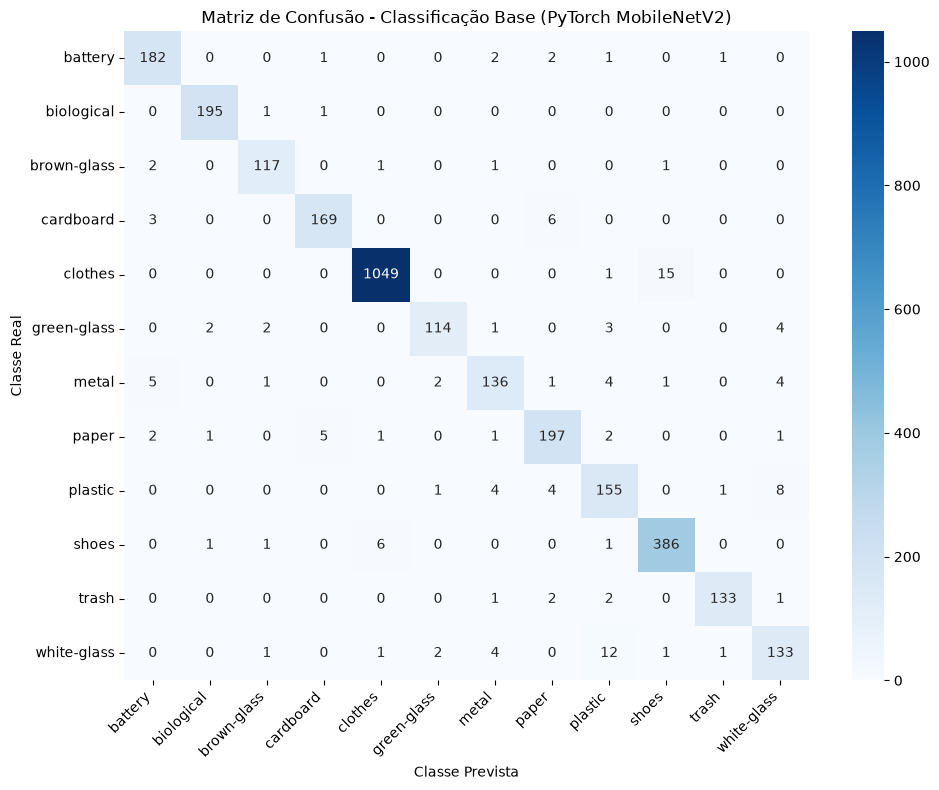

In [6]:
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matriz de Confusão - Classificação Base (PyTorch MobileNetV2)')
plt.xlabel('Classe Prevista')
plt.ylabel('Classe Real')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Active Learning + Human-in-the-Loop (HITL)

Carregar as Features salvas e preparar os Pools

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# 1. Carregar as features pré-calculadas
data = np.load('garbage_features.npz')
X = data['X']
y = data['y']
class_names = list(data['class_names'])
filenames = [fix_path(f) for f in data['filenames']]

print(f"Total de amostras carregadas: {X.shape[0]}")

# 2. Criar um split inicial: Labeled Pool (ex: 2% dos dados) e Unlabeled Pool (98%)
np.random.seed(42)
n_initial = int(0.02 * len(X))  # ~310 amostras rotuladas inicialmente

indices = np.arange(len(X))
np.random.shuffle(indices)

labeled_idx = list(indices[:n_initial])
unlabeled_idx = list(indices[n_initial:])

print(f"Amostras iniciais rotuladas (Labeled Pool): {len(labeled_idx)}")
print(f"Amostras no reservatório não rotulado (Unlabeled Pool): {len(unlabeled_idx)}")

Total de amostras carregadas: 15515
Amostras iniciais rotuladas (Labeled Pool): 310
Amostras no reservatório não rotulado (Unlabeled Pool): 15205


Definir as Estratégias de Seleção (Query Strategies)

In [8]:
def least_confidence_query(probs, n_samples=1):
    """Escolhe as instâncias onde a probabilidade da classe mais provável é menor."""
    uncertainties = 1 - np.max(probs, axis=1)
    return np.argsort(uncertainties)[-n_samples:]

def margin_query(probs, n_samples=1):
    """Escolhe as instâncias com menor diferença entre a 1ª e a 2ª classe mais provável."""
    sorted_probs = np.sort(probs, axis=1)
    margins = sorted_probs[:, -1] - sorted_probs[:, -2]
    return np.argsort(margins)[:n_samples]

def entropy_query(probs, n_samples=1):
    """Escolhe as instâncias com maior entropia (maior desordem nas probabilidades)."""
    # Adiciona ePS para evitar log(0)
    entropies = -np.sum(probs * np.log(probs + 1e-10), axis=1)
    return np.argsort(entropies)[-n_samples:]

def random_query(probs, n_samples=1):
    """Baseline: Escolha aleatória de instâncias."""
    return np.random.choice(len(probs), size=n_samples, replace=False)

Interface Interativa HITL no Jupyter (Jupyter Widgets)

In [9]:
import ipywidgets as widgets
from IPython.display import display, clear_output

class HITLLabeler:
    def __init__(self, X, y, filenames, class_names, labeled_idx, unlabeled_idx):
        self.X = X
        self.y = y
        self.filenames = filenames
        self.class_names = class_names
        self.labeled_idx = list(labeled_idx)
        self.unlabeled_idx = list(unlabeled_idx)
        
        self.model = LogisticRegression(max_iter=1000, random_state=42)
        self.model.fit(self.X[self.labeled_idx], self.y[self.labeled_idx])
        
        self.current_query_idx = None
        self.setup_ui()

    def setup_ui(self):
        self.out = widgets.Output()
        self.buttons = []
        
        # Botões para cada uma das 12 classes
        for i, name in enumerate(self.class_names):
            btn = widgets.Button(description=name, button_style='primary' if i % 2 == 0 else 'info')
            btn.on_click(self.make_label_callback(i))
            self.buttons.append(btn)
        
        self.grid = widgets.GridBox(self.buttons, layout=widgets.Layout(grid_template_columns="repeat(4, 200px)"))

    def make_label_callback(self, label_id):
        def callback(b):
            # Adicionar a amostra selecionada ao Labeled Pool com o rótulo do humano
            self.labeled_idx.append(self.current_query_idx)
            self.unlabeled_idx.remove(self.current_query_idx)
            
            # Re-treinar o modelo
            self.model.fit(self.X[self.labeled_idx], self.y[self.labeled_idx])
            
            # Próxima iteração
            self.next_iteration()
        return callback

    def next_iteration(self):
        with self.out:
            clear_output(wait=True)
            if len(self.unlabeled_idx) == 0:
                print("Todas as imagens foram rotuladas!")
                return
            
            # Calcular probabilidades para o Unlabeled Pool
            probs = self.model.predict_proba(self.X[self.unlabeled_idx])
            
            # Usar Least Confidence para encontrar a imagem com maior incerteza
            relative_query_pos = least_confidence_query(probs, n_samples=1)[0]
            self.current_query_idx = self.unlabeled_idx[relative_query_pos]
            
            # Mostrar imagem e incerteza
            img_path = self.filenames[self.current_query_idx]
            top_prob = np.max(probs[relative_query_pos])
            print(f"--- Human-in-the-Loop Active Learning ---")
            print(f"Imagens Rotuladas: {len(self.labeled_idx)} | Restantes: {len(self.unlabeled_idx)}")
            print(f"Confiança Atual do Modelo nesta imagem: {top_prob*100:.1f}%\n")
            
            display(Image.open(img_path).resize((250, 250)))

    def start(self):
        display(self.out)
        display(self.grid)
        self.next_iteration()

# Para Iniciar a Interface:
# labeler = HITLLabeler(X, y, filenames, class_names, labeled_idx, unlabeled_idx)
# labeler.start()

Código para a Simulação Automática

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from tqdm import tqdm

# 1. Carregar as features do ficheiro .npz
data = np.load('garbage_features.npz')
X = data['X']
y = data['y']
class_names = list(data['class_names'])

# 2. Definir as Query Strategies
def least_confidence_query(probs, n_samples=10):
    uncertainties = 1 - np.max(probs, axis=1)
    return np.argsort(uncertainties)[-n_samples:]

def margin_query(probs, n_samples=10):
    sorted_probs = np.sort(probs, axis=1)
    margins = sorted_probs[:, -1] - sorted_probs[:, -2]
    return np.argsort(margins)[:n_samples]

def entropy_query(probs, n_samples=10):
    entropies = -np.sum(probs * np.log(probs + 1e-10), axis=1)
    return np.argsort(entropies)[-n_samples:]

def random_query(probs, n_samples=10):
    return np.random.choice(len(probs), size=n_samples, replace=False)

# 3. Parâmetros do Experimento
N_INITIAL = 200      # Labeled pool inicial (~1.3% do dataset)
N_ITERATIONS = 40    # Número de iterações de rotulagem
BATCH_SIZE = 20      # Imagens rotuladas por iteração (Total final = 200 + 40*20 = 1000 amostras)

strategies = {
    'Random (Baseline)': random_query,
    'Least Confidence': least_confidence_query,
    'Margin Sampling': margin_query,
    'Entropy Sampling': entropy_query
}

# Fixar conjunto de Teste independente para avaliação (20% dos dados)
np.random.seed(42)
test_idx = np.random.choice(len(X), size=int(0.2 * len(X)), replace=False)
train_pool_idx = np.setdiff1d(np.arange(len(X)), test_idx)

X_test, y_test = X[test_idx], y[test_idx]

# Guardar histórico de acurácia por estratégia
results = {strat: [] for strat in strategies}
sample_counts = [N_INITIAL + i * BATCH_SIZE for i in range(N_ITERATIONS + 1)]

# 4. Executar a Simulação Comparativa
for name, query_fn in strategies.items():
    print(f"\nA simular Active Learning com estratégia: {name}...")
    
    # Criar split inicial idêntico para todas as estratégias
    np.random.seed(42)
    initial_labeled = np.random.choice(train_pool_idx, size=N_INITIAL, replace=False)
    
    labeled_idx = list(initial_labeled)
    unlabeled_idx = list(np.setdiff1d(train_pool_idx, initial_labeled))
    
    # Modelo
    clf = LogisticRegression(max_iter=1000, random_state=42)
    
    for iteration in tqdm(range(N_ITERATIONS + 1), desc=f"{name}"):
        # Treinar com o Labeled Pool atual
        clf.fit(X[labeled_idx], y[labeled_idx])
        
        # Avaliar no Test Set fixo
        y_pred = clf.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        results[name].append(acc)
        
        if iteration < N_ITERATIONS:
            # Prever probabilidades do Unlabeled Pool
            probs = clf.predict_proba(X[unlabeled_idx])
            
            # Escolher as PEORES/MAIS INCERTAS instâncias segundo a estratégia
            query_pos = query_fn(probs, n_samples=BATCH_SIZE)
            
            # Mover das unlabeled para as labeled
            selected_indices = [unlabeled_idx[p] for p in query_pos]
            labeled_idx.extend(selected_indices)
            
            # Remover selecionadas do unlabeled_idx
            unlabeled_idx = list(np.setdiff1d(unlabeled_idx, selected_indices))

print("\nSimulação concluída com sucesso!")



A simular Active Learning com estratégia: Random (Baseline)...


Random (Baseline): 100%|██████████| 41/41 [00:09<00:00,  4.40it/s]



A simular Active Learning com estratégia: Least Confidence...


Least Confidence: 100%|██████████| 41/41 [00:11<00:00,  3.55it/s]



A simular Active Learning com estratégia: Margin Sampling...


Margin Sampling: 100%|██████████| 41/41 [00:12<00:00,  3.18it/s]



A simular Active Learning com estratégia: Entropy Sampling...


Entropy Sampling: 100%|██████████| 41/41 [00:11<00:00,  3.71it/s]


Simulação concluída com sucesso!


Gerar o Gráfico de Comparação (Curvas de Aprendizagem)

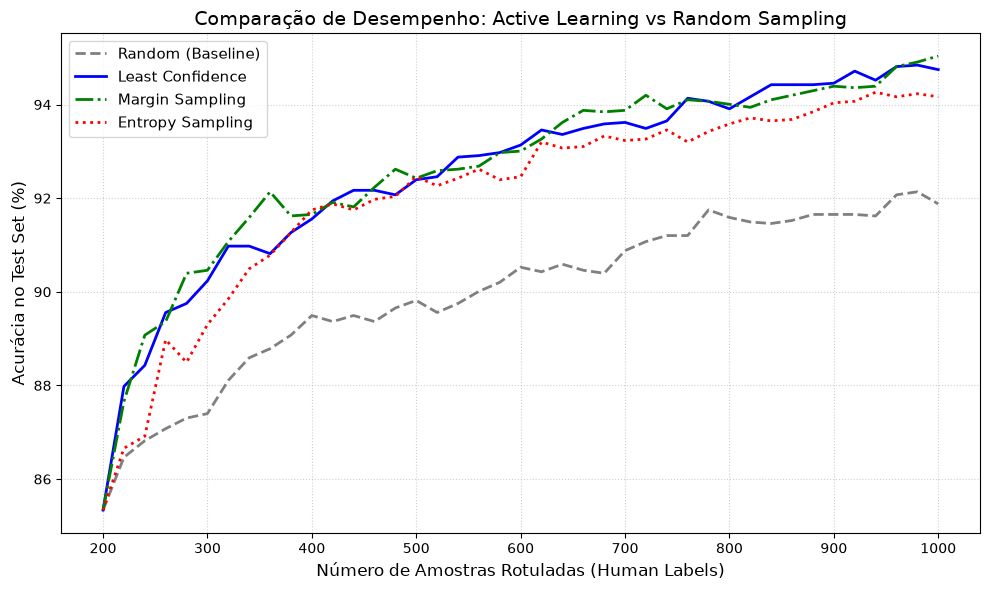

In [11]:
plt.figure(figsize=(10, 6))

styles = {
    'Random (Baseline)': ('--', 'gray'),
    'Least Confidence': ('-', 'blue'),
    'Margin Sampling': ('-.', 'green'),
    'Entropy Sampling': (':', 'red')
}

for name, acc_list in results.items():
    linestyle, color = styles[name]
    plt.plot(sample_counts, np.array(acc_list) * 100, label=name, linestyle=linestyle, color=color, linewidth=2)

plt.title('Comparação de Desempenho: Active Learning vs Random Sampling', fontsize=14)
plt.xlabel('Número de Amostras Rotuladas (Human Labels)', fontsize=12)
plt.ylabel('Acurácia no Test Set (%)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

Fase 3: Preparar a Interface Interativa Human-in-the-Loop (HITL)

In [14]:
import os
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output
from sklearn.linear_model import LogisticRegression

# 1. Carregar as features e caminhos dos ficheiros
data = np.load('garbage_features.npz')
X = data['X']
y_true = data['y']
class_names = list(data['class_names'])
filenames = [fix_path(f) for f in data['filenames']]

# 3. Criar os Pools Iniciais
np.random.seed(42)
N_START = 150

all_idx = np.arange(len(X))
np.random.shuffle(all_idx)

user_labeled_idx = list(all_idx[:N_START])
user_unlabeled_idx = list(all_idx[N_START:])
user_labels = {idx: y_true[idx] for idx in user_labeled_idx}

# Treinar modelo inicial
hitl_model = LogisticRegression(max_iter=1000, random_state=42)
hitl_model.fit(X[user_labeled_idx], [user_labels[i] for i in user_labeled_idx])

# 4. Criar os Elementos da Interface
img_widget = widgets.Image(format='jpeg', width=300, height=300)
info_label = widgets.HTML()
out = widgets.Output()

def get_next_uncertain_sample():
    probs = hitl_model.predict_proba(X[user_unlabeled_idx])
    uncertainties = 1 - np.max(probs, axis=1)
    most_uncertain_pos = np.argmax(uncertainties)
    return user_unlabeled_idx[most_uncertain_pos], probs[most_uncertain_pos]

current_sample_idx, current_probs = get_next_uncertain_sample()

def update_display():
    global current_sample_idx, current_probs
    
    # Atualizar imagem
    img_path = filenames[current_sample_idx]
    if os.path.exists(img_path):
        with open(img_path, "rb") as f:
            img_widget.value = f.read()
    else:
        info_label.value = f"<b style='color:red;'>Erro: Ficheiro não encontrado no caminho: {img_path}</b>"
        return

    # Atualizar texto explicativo
    top_pred_class = class_names[np.argmax(current_probs)]
    confidence = np.max(current_probs) * 100
    
    info_label.value = f"""
    <h3>=== SESSÃO INTERATIVA HUMAN-IN-THE-LOOP ===</h3>
    <p><b>Amostras Rotuladas:</b> {len(user_labeled_idx)} | <b>Restantes:</b> {len(user_unlabeled_idx)}</p>
    <p><b>Previsão do Modelo:</b> <span style='color:blue;'>{top_pred_class}</span> (Confiança: <b>{confidence:.1f}%</b>)</p>
    <p><i>Qual é a classe correta deste resíduo? Clica no botão correspondente abaixo:</i></p>
    """

def on_button_click(class_id):
    global current_sample_idx, current_probs
    
    # Guardar label e re-treinar
    user_labels[current_sample_idx] = class_id
    user_labeled_idx.append(current_sample_idx)
    user_unlabeled_idx.remove(current_sample_idx)
    
    hitl_model.fit(X[user_labeled_idx], [user_labels[i] for i in user_labeled_idx])
    
    # Próxima imagem
    current_sample_idx, current_probs = get_next_uncertain_sample()
    update_display()

# Criar os botões das 12 classes
buttons = []
for i, name in enumerate(class_names):
    btn = widgets.Button(
        description=name,
        button_style='primary' if i % 2 == 0 else 'info',
        layout=widgets.Layout(width='160px', height='38px', margin='3px')
    )
    btn.on_click(lambda b, cid=i: on_button_click(cid))
    buttons.append(btn)

grid = widgets.GridBox(buttons, layout=widgets.Layout(grid_template_columns="repeat(4, 170px)"))

# Apresentar a interface
display(info_label)
display(img_widget)
display(grid)

# Carregar a primeira imagem
update_display()

HTML(value='')

Image(value=b'', format='jpeg', height='300', width='300')

GridBox(children=(Button(button_style='primary', description=np.str_('battery'), layout=Layout(height='38px', …